# MobiCar: product funnel analysis

[↩ Project](../README.md)

Case study for the T-Bank internship selection process. The task is to find the stage where conversion to the first ride declined, show it on one chart and suggest checks to identify the causes.

## Data

The table covers 56 days from 6 January to 2 March 2025, grouped into eight weeks. Each day has user counts for six stages.

**Installation → Registration → Search → Car view → Booking → First ride**

The data is loaded from [CSV](../data/funnel-daily.csv). The same table is available in [Excel](../data/funnel-data.xlsx).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook can run from the project root or the notebooks folder
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

df = pd.read_csv(root / "data/funnel-daily.csv", parse_dates=["Дата"])
df = df.rename(columns={'Дата': 'Date', 'Неделя': 'Week', 'Установки': 'Installations', 'Регистрации': 'Registrations', 'Открыли поиск': 'Opened search', 'Просмотрели авто': 'Viewed car', 'Забронировали': 'Bookings', 'Первая поездка': 'First ride'})
df["Week"] = df["Week"].str.replace("Неделя", "Week", regex=False)
df.head()

,Date,Week,Installations,Registrations,Opened search,Viewed car,Bookings,First ride
0,2025-01-06,Week 1,206,130,91,70,57,51
1,2025-01-07,Week 1,216,138,98,73,55,48
2,2025-01-08,Week 1,181,117,86,69,52,46
3,2025-01-09,Week 1,212,134,101,83,64,54
4,2025-01-10,Week 1,218,143,97,73,60,53


## Calculating conversion rates

**Daily conversion = users at the next stage / users at the previous stage × 100%.**

For example, registration-to-search conversion shows the share of registered users who opened car search.

For each week, I take the average of the daily conversion rates. Each day therefore has equal weight. Overall conversion covers the journey from installation to the first ride.

In [2]:
conversion = pd.DataFrame({
    "Installation → Registration": df["Registrations"] / df["Installations"],
    "Registration → Search": df["Opened search"] / df["Registrations"],
    "Search → Car view": df["Viewed car"] / df["Opened search"],
    "Car view → Booking": df["Bookings"] / df["Viewed car"],
    "Booking → First ride": df["First ride"] / df["Bookings"],
    "Installation → First ride": df["First ride"] / df["Installations"],
}) * 100

weekly = conversion.groupby(df["Week"]).mean()
weekly.index.name = "Week"
weekly.columns.name = "Conversion, %"
weekly.T.round(2)

Week,Week 1,Week 2,Week 3,Week 4,Week 5,Week 6,Week 7,Week 8
"Conversion, %",,,,,,,,
Installation → Registration,65.34,65.87,67.89,67.99,66.70,67.94,66.94,67.53
Registration → Search,72.31,70.78,74.18,72.08,72.76,70.95,49.35,50.33
Search → Car view,79.27,78.84,80.52,79.81,79.80,78.98,84.06,81.26
Car view → Booking,78.59,78.44,75.73,75.60,78.97,79.70,79.32,79.56
Booking → First ride,87.12,89.56,86.11,87.77,87.35,90.74,84.26,89.38
Installation → First ride,25.66,25.89,26.42,25.93,26.73,27.48,18.54,19.68


## Weekly trends

The chart shows five transitions between consecutive stages. Registration to search is highlighted in red.

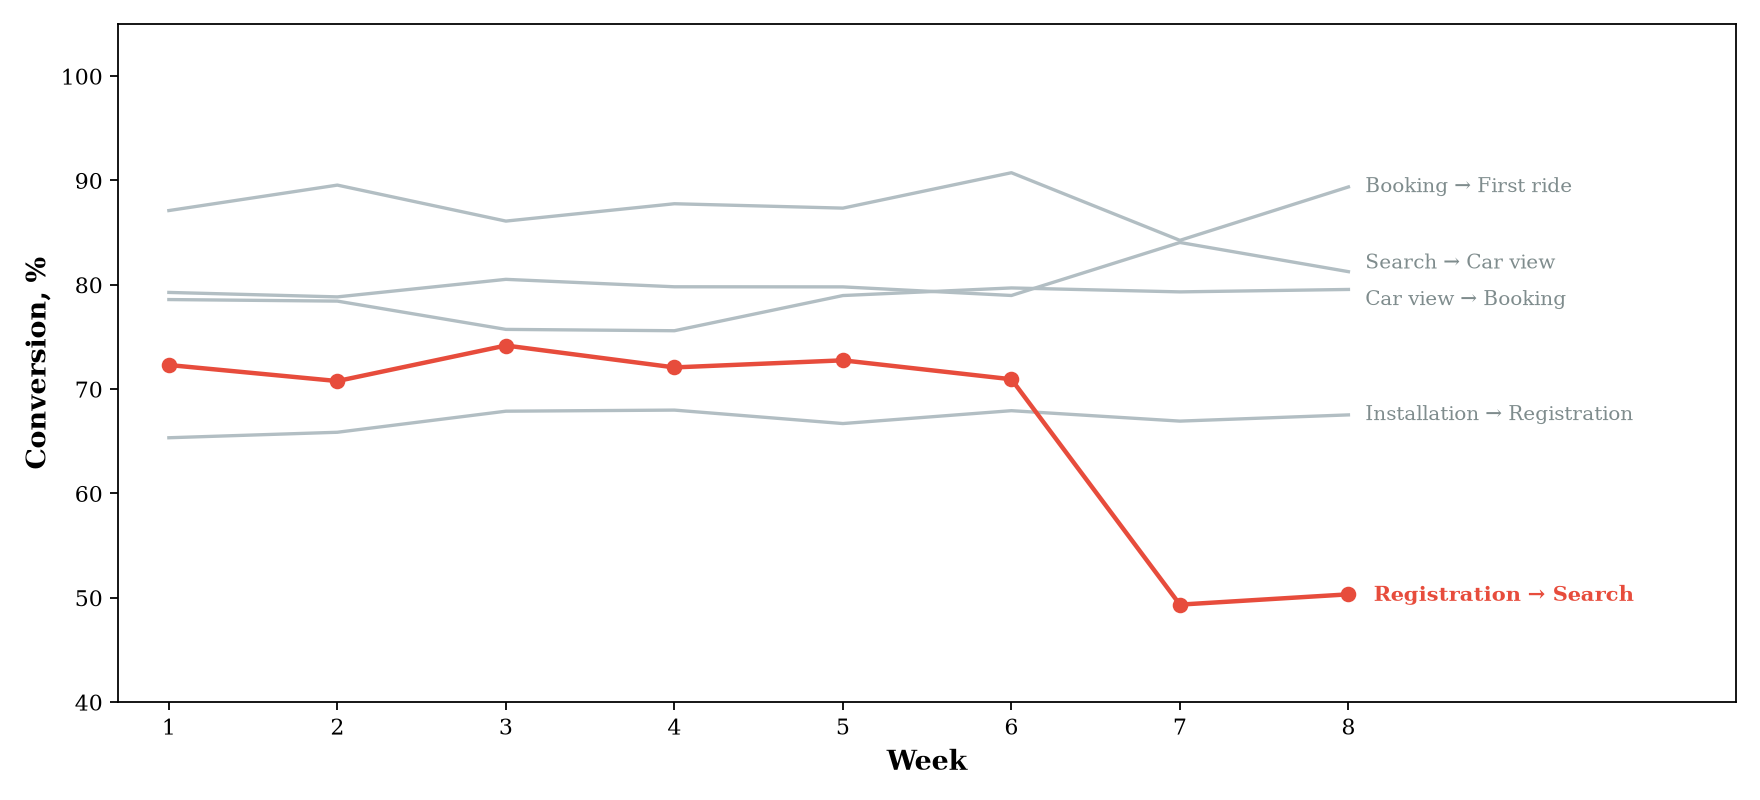

In [3]:
plt.rc("font", family="serif")
fig, ax = plt.subplots(figsize=(11, 5))
weeks = range(1, len(weekly) + 1)
search = "Registration → Search"

labels = {
    "Installation → Registration": ("Installation → Registration", 0),
    "Search → Car view": ("Search → Car view", 0.8),
    "Car view → Booking": ("Car view → Booking", -1),
    "Booking → First ride": ("Booking → First ride", 0),
}
for stage, (label, offset) in labels.items():
    ax.plot(weeks, weekly[stage], linewidth=1.5, color="#b2bec3")
    # Offset labels where the lines end close together
    ax.text(8.1, weekly[stage].iloc[-1] + offset, label,
            fontsize=9, color="#7f8c8d", va="center")

ax.plot(weeks, weekly[search], marker="o", linewidth=2, color="#e74c3c")
ax.text(8.15, weekly[search].iloc[-1] - 0.1, search,
        fontsize=9.5, color="#e74c3c", va="center", fontweight="bold")

ax.set_xticks(weeks)
ax.set_xlabel("Week", fontsize=12, fontweight="bold")
ax.set_ylabel("Conversion, %", fontsize=12, fontweight="bold")
ax.set_ylim(40, 105)
ax.set_xlim(0.7, 10.3)
fig.tight_layout()
fig.savefig(root / "assets/funnel.en.png", dpi=160)
plt.show()

## Where conversion dropped

I compare weeks 6 and 7. Changes in the table are expressed in percentage points.

In [4]:
changes = pd.DataFrame({
    "Week 6, %": weekly.loc["Week 6"],
    "Week 7, %": weekly.loc["Week 7"],
})
changes["Change, pp"] = changes["Week 7, %"] - changes["Week 6, %"]
changes.round(2)

,"Week 6, %","Week 7, %","Change, pp"
"Conversion, %",,,
Installation → Registration,67.94,66.94,-1.00
Registration → Search,70.95,49.35,-21.60
Search → Car view,78.98,84.06,5.08
Car view → Booking,79.70,79.32,-0.38
Booking → First ride,90.74,84.26,-6.48
Installation → First ride,27.48,18.54,-8.94


**The largest drop between consecutive stages occurred at Registration → Search: from 70.95% to 49.35%, a decline of 21.60 percentage points.** Conversion remained around 50% in week 8.

Overall conversion from installation to the first ride fell from **27.48% to 18.54%, a decline of 8.94 percentage points**, between weeks 6 and 7. The first step is to investigate what prevents users from opening search after registration.

## Checking weekly totals

I also calculate the share of users who opened search among all users who registered that week. I divide the weekly number of users who opened search by the weekly number of registrations. Days with more registrations have more weight in this calculation.

In [5]:
counts = df.groupby("Week")[["Registrations", "Opened search"]].sum()
comparison = pd.DataFrame({
    "Mean daily conversion, %": weekly["Registration → Search"],
    "Using weekly totals, %": counts["Opened search"] / counts["Registrations"] * 100,
})
comparison.round(2)

,"Mean daily conversion, %","Using weekly totals, %"
Week,,
Week 1,72.31,72.30
Week 2,70.78,70.85
Week 3,74.18,74.10
Week 4,72.08,71.97
Week 5,72.76,72.80
Week 6,70.95,70.82
Week 7,49.35,49.36
Week 8,50.33,50.34


Using weekly totals, registration-to-search conversion fell from **70.82% to 49.36%**. Both methods identify the same transition as the source of the drop.